# Day 08: RAG from scratch, a handbook chatbot

**RAG = Retrieval-Augmented Generation.**
1. **Retrieve:** find the few pieces of our document that match the question.
2. **Augment:** paste them into the prompt.
3. **Generate:** the LLM answers from them.

Our document: `data/nimbus_handbook.pdf`, the 43-page handbook of **Nimbus Labs, a made-up company**. No LLM has seen it, so it *has* to use our document.

Diagram: `../diagrams/rag-pipeline.excalidraw`

| § | Topic |
|---|---|
| 0 | Setup |
| 1 | A plain LLM can't answer |
| 2 | Fine-tuning vs RAG vs long context |
| 3 | **Ingestion**: PDF → OCR → .md file → chunks → embeddings → index |
| 4 | **Retrieval**: find the closest chunks |
| 5 | **Generation**: chunks + question → answer |
| 6 | Chatbot with memory |
| 7 | Why not paste the whole PDF? |
| 8 | Problems of basic RAG |
| 9 | Recap and homework |
| 10 | **Live chat** (streaming) |

Needs `OPENAI_API_KEY` in `.env`. (`MISTRAL_API_KEY` only if you delete `data/ocr_mistral.json`.)

In [4]:
!pip install numpy pandas pymupdf dotenv IPython openai

  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl.metadata (595 bytes)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 6.3 MB/s  0:00:01a 0:00:0136m0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 MB 3.5 MB/s  0:00:19 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.8 MB/s  0:00:003.9 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 4.8 MB/s  0:00:04a 0:00:010:00:01:02
Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl (456 kB)
Using cached flatbuffers-25.12.19-py2.py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [pymupdf]━ 10/11 [pymupdf]nnxruntime]


## 0. Setup

In [5]:
import json, os, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import pymupdf
from dotenv import load_dotenv
from IPython.display import Image, display
from openai import OpenAI

load_dotenv()
client = OpenAI()

PDF_PATH = Path("data/nimbus_handbook.pdf")
OCR_CACHE = Path("data/ocr_mistral.json")
MD_PATH = Path("data/nimbus_handbook.md")
INDEX_DIR = Path("index")

CHAT_MODEL = "gpt-6-luna"                        # checked 2026-10-19
EMBED_MODEL = "text-embedding-3-small"

In [6]:
def ask_llm(input, instructions="You are a helpful assistant."):
    response = client.responses.create(
        model=CHAT_MODEL,
        instructions=instructions,
        input=input,
        reasoning={"effort": "none"},
    )
    return response

## 1. A plain LLM can't answer

The model only knows its training data. It has never seen our handbook.

Real answer (handbook): **24 earned leaves a year, carry forward up to 15.**

In [7]:
question = "How many earned leaves do I get per year at Nimbus Labs, and how many can I carry forward?"
plain_answer = ask_llm(question).output_text
print(plain_answer)

I don’t have access to Nimbus Labs’ leave policy, so I can’t confirm those numbers. Check your employee handbook or HR portal, or ask HR.


It either **guesses** (hallucination) or says **"I don't know"**.

Problems of a plain LLM:
1. Hallucinates
2. Knowledge cutoff
3. No private data
4. Not updated
5. No sources

**Fix:** put the right text *into the prompt*. That's RAG.

## 2. Fine-tuning vs RAG vs long context

| | **Fine-tuning** | **RAG** | **Long context** |
|---|---|---|---|
| What | Re-train the model on your data | Search your data, add the best chunks to the prompt | Put the whole document in every prompt |
| Data changed? | Re-train | Re-index the file | Nothing to do |
| Sources? | No | Yes | Hard |
| Cost | High | Low | High per question |
| Scale | Any | Millions of pages | Only what fits |
| Good for | **Style, format, tone** | **Knowledge** | One small document |

**RAG for knowledge, fine-tuning for style.** OpenAI's guide: https://developers.openai.com/api/docs/guides/model-optimization (it also says, checked 2026-10-19, that fine-tuning is winding down for new users).

## 3. Ingestion

Runs once (and again when the document changes):

```
PDF → OCR → clean → .md file → chunks → embeddings → index
```

### 3.1 Look at the PDF

43 pages


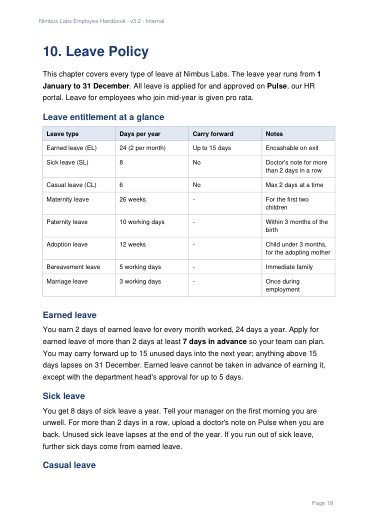

In [8]:
pdf = pymupdf.open(PDF_PATH)
print(len(pdf), "pages")

def show_page(page_number):
    display(Image(pdf[page_number - 1].get_pixmap(dpi=45).tobytes("png")))

show_page(18)

Some PDFs have a **text layer**, some are just **images** (scans). Which pages have no text?

In [9]:
for i, page in enumerate(pdf):
    if page.get_text().strip() == "":
        print("No text on page", i + 1)

No text on page 20


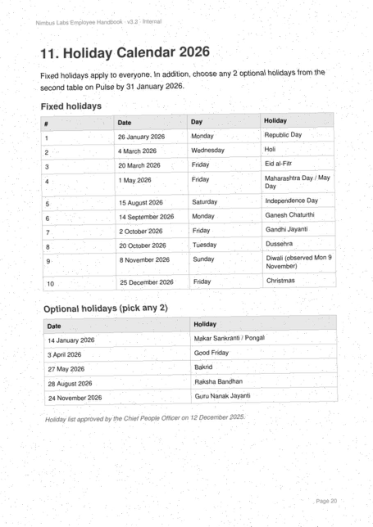

''


In [10]:
show_page(20)
print(repr(pdf[19].get_text()))

Page 20 is a **scan**: a table we can see, but no text a program can read. So we use **OCR**.

### 3.2 OCR: PDF → markdown

**Mistral OCR** returns markdown per page (headings as `#`, tables as `| a | b |`). OCR costs money, so we save the result in `data/ocr_mistral.json` and reuse it.

In [11]:
def get_mistral_ocr_res(pdf_path):
    from mistralai.client import Mistral
    mistral = Mistral(api_key=os.environ["MISTRAL_API_KEY"])
    uploaded = mistral.files.upload(file={"file_name": pdf_path.name, "content": pdf_path.read_bytes()}, purpose="ocr")
    signed = mistral.files.get_signed_url(file_id=uploaded.id, expiry=1)
    result = mistral.ocr.process(model="mistral-ocr-latest", document={"type": "document_url", "document_url": signed.url})
    mistral.files.delete(file_id=uploaded.id)
    return [p.markdown for p in result.pages]

In [12]:
if OCR_CACHE.exists():
    pages = json.loads(OCR_CACHE.read_text())
else:
    pages = get_mistral_ocr_res(PDF_PATH)
    OCR_CACHE.write_text(json.dumps(pages, indent=1, ensure_ascii=False))

print(len(pages), "pages")

43 pages


The scanned page 20 after OCR, a real table:

In [9]:
print(pages[19][:1200])

Nimbus Labs Employee Handbook - v3.2 - Internal

## 11. Holiday Calendar 2026

Fixed holidays apply to everyone. In addition, choose any 2 optional holidays from the second table on Pulse by 31 January 2026.

### Fixed holidays

|  # | Date | Day | Holiday  |
| --- | --- | --- | --- |
|  1 | 26 January 2026 | Monday | Republic Day  |
|  2 | 4 March 2026 | Wednesday | Holi  |
|  3 | 20 March 2026 | Friday | Eid al-Fitr  |
|  4 | 1 May 2026 | Friday | Maharashtra Day / May Day  |
|  5 | 15 August 2026 | Saturday | Independence Day  |
|  6 | 14 September 2026 | Monday | Ganesh Chaturthi  |
|  7 | 2 October 2026 | Friday | Gandhi Jayanti  |
|  8 | 20 October 2026 | Tuesday | Dussehra  |
|  9 | 8 November 2026 | Sunday | Diwali (observed Mon 9 November)  |
|  10 | 25 December 2026 | Friday | Christmas  |

### Optional holidays (pick any 2)

|  Date | Holiday  |
| --- | --- |
|  14 January 2026 | Makar Sankranti / Pongal  |
|  3 April 2026 | Good Friday  |
|  27 May 2026 | Bakrid  |
|  28 Au

**Free option: Tesseract** (runs on your laptop). It gives plain text, and on page 20 it made mistakes: "Tuesday" → `-tesneciny`, "Good Friday" → `Good Disasill`.

**Garbage in, garbage out:** bad OCR = bad chatbot.

### 3.3 Clean and save the .md file

Every page has the same header line (`Nimbus Labs Employee Handbook · v3.2 · Internal`) and footer (`Page 18`). They add nothing, so we remove them. We also skip pages 1 to 3 (cover and contents).

In [13]:
def clean_page(markdown):
    lines = []
    for line in markdown.splitlines():
        if "Nimbus Labs Employee Handbook" in line:          # header
            continue
        if re.fullmatch(r"Page \d+", line.strip()):          # footer
            continue
        lines.append(line)
    return "\n".join(lines).strip()

def create_markdown_file(pages, output_filename):
    with open(output_filename, "w") as f:
        for page in pages[3:]:                               # skip cover + contents
            f.write(clean_page(page) + "\n\n")

create_markdown_file(pages, MD_PATH)
md_lines = MD_PATH.read_text().splitlines()
print(f"Saved {MD_PATH}: {len(md_lines)} lines")

Saved data/nimbus_handbook.md: 868 lines


Open `data/nimbus_handbook.md` in VS Code: this is everything our chatbot knows.

### 3.4 Chunk: 50 lines at a time

Why chunks? One vector for the whole handbook is too blurry, and we want to send the LLM only the relevant parts.

- **chunk_size = 50** lines per chunk
- **overlap = 20** lines shared with the next chunk, so nothing is lost at the cut

In [14]:
def chunk_md_file(file_path, chunk_size=50, overlap=20):
    with open(file_path) as f:
        lines = f.readlines()

    chunks = []
    start = 0
    while start < len(lines):
        end = min(start + chunk_size, len(lines))
        chunks.append({
            "chunk_id": len(chunks),
            "start_line": start + 1,
            "end_line": end,
            "filename": file_path.name,
            "text": "".join(lines[start:end]),
        })
        if end == len(lines):
            break
        start = end - overlap
    return chunks

In [15]:
chunks = chunk_md_file(MD_PATH)
print("Total lines :", len(md_lines))
print("Total chunks:", len(chunks))

Total lines : 868
Total chunks: 29


All chunks:

In [16]:
pd.set_option("display.max_rows", 100)
pd.DataFrame([
    {"chunk_id": c["chunk_id"], "start_line": c["start_line"], "end_line": c["end_line"],
     "characters": len(c["text"]), "starts with": c["text"].strip()[:60].replace("\n", " ")}
    for c in chunks
])

,chunk_id,start_line,end_line,characters,starts with
0,0,1,50,3451,# 1. Welcome to Nimbus Labs Nimbus Labs Priva...
1,1,31,80,3259,Part A: Company Policies ## 2. Code of Conduc...
2,2,61,110,3037,## Reporting a concern Report concerns to you...
3,3,91,140,2838,"needs approval from both HR and Finance, becau..."
4,4,121,170,2917,### Security incidents If you click a suspici...
5,5,151,200,3068,| --- | --- | --- | | Accounting records of a...
6,6,181,230,3458,Both offices are wheelchair accessible. Employ...
7,7,211,260,3091,### Other grievances For any other workplace ...
8,8,241,290,3035,## Hiring Every open role has a written job d...
9,9,271,320,2937,| Leave type | Days per year | Carry forward ...


One chunk in full:

In [17]:
print(chunks[9]["text"])


|  Leave type | Days per year | Carry forward | Notes  |
| --- | --- | --- | --- |
|  Earned leave (EL) | 24 (2 per month) | Up to 15 days | Encashable on exit  |
|  Sick leave (SL) | 8 | No | Doctor's note for more than 2 days in a row  |
|  Casual leave (CL) | 6 | No | Max 2 days at a time  |
|  Maternity leave | 26 weeks | - | For the first two children  |
|  Paternity leave | 10 working days | - | Within 3 months of the birth  |
|  Adoption leave | 12 weeks | - | Child under 3 months, for the adopting mother  |
|  Bereavement leave | 5 working days | - | Immediate family  |
|  Marriage leave | 3 working days | - | Once during employment  |

## Earned leave

You earn 2 days of earned leave for every month worked, 24 days a year. Apply for earned leave of more than 2 days at least **7 days in advance** so your team can plan. You may carry forward up to 15 unused days into the next year; anything above 15 days lapses on 31 December. Earned leave cannot be taken in advance of earning 

**Pros:** very simple. **Cons:** cuts in the middle of sections and tables. A better way: split at headings (`#`, `##`). That's homework.

### 3.5 Embed: text → vectors

An **embedding** turns text into a list of numbers (a **vector**, 1,536 numbers). Similar meaning → similar vectors, even with different words.

**Cosine similarity**: 1 = same meaning, 0 = unrelated. OpenAI vectors have length 1, so it's just a dot product (https://developers.openai.com/api/docs/guides/embeddings).

In [18]:
def embed(texts):
    response = client.embeddings.create(model=EMBED_MODEL, input=texts)
    return np.array([d.embedding for d in response.data])

A small demo:

In [19]:
demo = ["How many days off do I get in a year?",
        "Annual leave entitlement for employees",
        "List of public holidays",
        "Best biryani in Bengaluru"]
v = embed(demo)
print("shape:", v.shape)
pd.DataFrame(v @ v.T, index=demo, columns=[d[:20] + "…" for d in demo]).round(2)

shape: (4, 1536)


,How many days off do…,Annual leave entitle…,List of public holid…,Best biryani in Beng…
How many days off do I get in a year?,1.00,0.45,0.37,0.03
Annual leave entitlement for employees,0.45,1.00,0.34,0.09
List of public holidays,0.37,0.34,1.00,0.14
Best biryani in Bengaluru,0.03,0.09,0.14,1.00


"Days off" and "annual leave" are close with almost no shared words: **semantic search**. Biryani is far from everything.

Now embed all chunks:

In [20]:
vectors = embed([c["text"] for c in chunks])
print(vectors.shape)

(29, 1536)


### 3.6 Store: our vector DB

For each chunk we store **the vector + the text**. A numpy file is enough for a few dozen chunks. For millions, use a real vector DB (pgvector, Qdrant, Chroma, Pinecone): coming in the next classes.

In [21]:
def save_index(chunks, vectors):
    INDEX_DIR.mkdir(exist_ok=True)
    np.save(INDEX_DIR / "vectors.npy", vectors)
    (INDEX_DIR / "chunks.json").write_text(json.dumps(chunks, indent=1, ensure_ascii=False))

def load_index():
    chunks = json.loads((INDEX_DIR / "chunks.json").read_text())
    vectors = np.load(INDEX_DIR / "vectors.npy")
    return chunks, vectors

save_index(chunks, vectors)
CHUNKS, VECTORS = load_index()
print(len(CHUNKS), "chunks,", VECTORS.shape, "vectors")

29 chunks, (29, 1536) vectors


## 4. Retrieval

For every question:
1. Embed the question (same model!)
2. Score it against every chunk (dot product)
3. Keep the **top k**

In [33]:
def search(query, k=3):
    query_vector = embed([query])[0]
    scores = VECTORS @ query_vector
    best = np.argsort(-scores)[:k]
    return [{**CHUNKS[i], "score": float(scores[i])} for i in best]

def show(hits):
    for h in hits:
        print(f'chunk {h["chunk_id"]:<3} score {h["score"]:.3f}')

show(search("How many sick leave can i have?"))

chunk 9   score 0.447
chunk 8   score 0.399
chunk 10  score 0.350


In [26]:
show(search("Can I work from home on Fridays?"))
print()
show(search("Is Dussehra a holiday this year?"))    # from the scanned page, thanks to OCR

chunk 26  score 0.415
chunk 1   score 0.400
chunk 27  score 0.368

chunk 10  score 0.293
chunk 9   score 0.282
chunk 11  score 0.257


## 5. Generation

Put the chunks in the prompt, with rules: answer only from them, say when you don't know.

In [27]:
SYSTEM_PROMPT = '''You are the Nimbus Labs HR helpdesk assistant. You answer employees' questions using the Nimbus Labs Employee Handbook.

# Rules
- Answer ONLY from the handbook chunks inside <context>.
- If the chunks don't contain the answer, say: "I couldn't find that in the handbook. Please ask the People team at people@nimbuslabs.example." Don't guess.
- Mention the chunk you used, like [chunk 10].
- If two chunks disagree, the Addendum is newer and wins. Say that the policy changed.
- Keep answers short: 2 to 5 sentences.'''

In [29]:
def build_prompt(question, hits):
    context = ""
    for h in hits:
        context += f'<chunk id="{h["chunk_id"]}">\n{h["text"]}\n</chunk>\n\n'
    return f"<context>\n{context}</context>\n\nQuestion: {question}"

def rag_answer(question, k=3):
    hits = search(question, k)
    answer = ask_llm(build_prompt(question, hits), SYSTEM_PROMPT).output_text
    return answer, hits

In [31]:
question = "How many sick leave can i have?"

What the LLM receives:

In [32]:
print(build_prompt(question, search(question))[:1500], "\n...")

<context>
<chunk id="9">

|  Leave type | Days per year | Carry forward | Notes  |
| --- | --- | --- | --- |
|  Earned leave (EL) | 24 (2 per month) | Up to 15 days | Encashable on exit  |
|  Sick leave (SL) | 8 | No | Doctor's note for more than 2 days in a row  |
|  Casual leave (CL) | 6 | No | Max 2 days at a time  |
|  Maternity leave | 26 weeks | - | For the first two children  |
|  Paternity leave | 10 working days | - | Within 3 months of the birth  |
|  Adoption leave | 12 weeks | - | Child under 3 months, for the adopting mother  |
|  Bereavement leave | 5 working days | - | Immediate family  |
|  Marriage leave | 3 working days | - | Once during employment  |

## Earned leave

You earn 2 days of earned leave for every month worked, 24 days a year. Apply for earned leave of more than 2 days at least **7 days in advance** so your team can plan. You may carry forward up to 15 unused days into the next year; anything above 15 days lapses on 31 December. Earned leave cannot be tak

In [34]:
answer, hits = rag_answer(question)
print("Without RAG:", plain_answer)
print("\nWith RAG:   ", answer)

Without RAG: I don’t have access to Nimbus Labs’ leave policy, so I can’t confirm those numbers. Check your employee handbook or HR portal, or ask HR.

With RAG:    You get 8 days of sick leave per year. [chunk 9]


In [37]:
for q in ["What is the daily allowance for a trip to Pune?",
          "My father passed away. How many days off can I take?",
          "Is Dussehra a holiday, and on which day?"]:
    answer, hits = rag_answer(q)
    print(f"Q: {q}\nA: {answer}\n")

Q: What is the daily allowance for a trip to Pune?
A: For Pune (Tier 2), the daily allowance is **Rs. 1,200**. If meals are provided, it is halved for that day. [chunk 21]

Q: My father passed away. How many days off can I take?
A: You can take 5 working days of bereavement leave for an immediate family member. [chunk 9]

Q: Is Dussehra a holiday, and on which day?
A: Yes. Dussehra is a fixed holiday on Tuesday, 20 October 2026. [chunk 10]



## 6. Chatbot with memory

We keep a `history` of questions and answers (not the chunks).

Problem: a follow-up like *"can I carry them forward?"* is a bad search query: what is "them"? Fix: **query rewriting**. The LLM rewrites the follow-up into a full question first.

In [38]:
def rewrite_question(question, history):
    if not history:
        return question
    conversation = "\n".join(f"{m['role']}: {m['content']}" for m in history[-4:])
    prompt = f"Conversation:\n{conversation}\n\nFollow-up question: {question}"
    instructions = "Rewrite the follow-up question as one standalone search query for the company handbook. Reply with the query only."
    return ask_llm(prompt, instructions).output_text.strip()

def chat_turn(question, history, rewrite=True):
    query = rewrite_question(question, history) if rewrite else question
    hits = search(query)
    messages = history + [{"role": "user", "content": build_prompt(question, hits)}]
    answer = ask_llm(messages, SYSTEM_PROMPT).output_text

    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})
    print(f"You: {question}\n  search: {query!r} → chunks {[h['chunk_id'] for h in hits]}\nBot: {answer}\n")

**Without** rewriting:

In [39]:
history = []
chat_turn("How many sick leaves do I get?", history, rewrite=False)
chat_turn("Can I carry them forward to next year?", history, rewrite=False)

You: How many sick leaves do I get?
  search: 'How many sick leaves do I get?' → chunks [9, 8, 10]
Bot: You get 8 sick leave days per year. [chunk 8]

You: Can I carry them forward to next year?
  search: 'Can I carry them forward to next year?' → chunks [26, 9, 10]
Bot: No. Unused sick leave doesn’t carry forward and lapses at the end of the year. [chunk 9]



**With** rewriting (see the search query change). Here big chunks found the answer anyway; with small chunks or many documents, the raw follow-up fails.

In [40]:
history = []
chat_turn("How many sick leaves do I get?", history)
chat_turn("Can I carry them forward to next year?", history)

You: How many sick leaves do I get?
  search: 'How many sick leaves do I get?' → chunks [9, 8, 10]
Bot: You get 8 sick leave days per year. [chunk 8]

You: Can I carry them forward to next year?
  search: 'Can unused sick leave days be carried forward to the next year?' → chunks [9, 10, 8]
Bot: No. Unused sick leave lapses at the end of the year and cannot be carried forward. [chunk 9]



## 7. Why not paste the whole PDF?

The handbook is small enough to fit. Let's compare:

In [41]:
q = "What is the notice period after probation?"

whole = ask_llm(f"<context>\n{MD_PATH.read_text()}\n</context>\n\nQuestion: {q}", SYSTEM_PROMPT)
rag = ask_llm(build_prompt(q, search(q)), SYSTEM_PROMPT)

print("Whole file:", whole.usage.input_tokens, "input tokens →", whole.output_text)
print("RAG: ", rag.usage.input_tokens, "input tokens →", rag.output_text)

Whole file: 10604 input tokens → After probation, the notice period is **60 days** for both you and the company. [chunk 19]
RAG:  2106 input tokens → After probation, the notice period is 60 days for both you and the company. [chunk 17]


Both right, but the whole file costs about 3 times more tokens (10,604 vs 3,328 in our run) **on every question**.

Whole document is OK for: one small document, few users.
RAG for: many documents, many questions, per-user access.

## 8. Problems of basic RAG

### 8.1 The answer isn't in the document

The bot must say "I don't know". Look at the best score: it's low.

In [42]:
for q in ["Can I bring my dog to the office?", "What is the capital of Australia?"]:
    answer, hits = rag_answer(q)
    print(f"Q: {q}\nA: {answer}\nbest score: {hits[0]['score']:.3f}\n")

Q: Can I bring my dog to the office?
A: I couldn't find that in the handbook. Please ask the People team at people@nimbuslabs.example.
best score: 0.331

Q: What is the capital of Australia?
A: I couldn't find that in the handbook. Please ask the People team at people@nimbuslabs.example.
best score: 0.115



Search **always** returns k chunks, even if none is relevant. Fix: a minimum score.

### 8.2 Exact codes

Embeddings understand *meaning*, not exact strings like `CC-400` (a cost centre code).

In [43]:
print("Chunks that contain CC-400:", [c["chunk_id"] for c in CHUNKS if "CC-400" in c["text"]])
show(search("CC-400", k=3))

Chunks that contain CC-400: [23, 24]
chunk 22  score 0.204
chunk 23  score 0.198
chunk 24  score 0.193


In our run, chunk 22 came **first**, and it doesn't even contain `CC-400`. All scores are about 0.2, against about 0.5 for a normal question. For an embedding model, "CC-400" has no meaning.

Fix: **keyword search (BM25)** + vectors = **hybrid search**. Later class.

### 8.3 Old and new versions

Paternity leave was 10 days and the **Addendum** changed it to 15. If the Addendum chunk isn't retrieved, the bot gives the old answer.

In [44]:
print("Chunks with the new rule:", [c["chunk_id"] for c in CHUNKS if "10 to **15 working days" in c["text"]])
q = "How many days of paternity leave do I get?"
for k in [1, 5]:
    answer, hits = rag_answer(q, k=k)
    print(f"\nk={k}: chunks {[h['chunk_id'] for h in hits]}\n{answer}")

Chunks with the new rule: [26, 27]

k=1: chunks [9]
You get 10 working days of paid paternity leave, to be taken within 3 months of the birth or adoption. [chunk 9]

k=5: chunks [9, 8, 10, 17, 27]
From 1 July 2026, you get **15 working days** of paternity leave, to be taken within 6 months of the birth or adoption. The policy changed from 10 working days. [chunk 27]


**k=1:** only chunk 9 (old rule), so the bot says 10 days, confidently.
**k=5:** chunk 27 (Addendum) gets in, so the bot says 15 days.

Fix: remove old documents, store dates in metadata, retrieve enough chunks.

### 8.4 Questions that need many chunks

Top 5 = at most 5 chunks of evidence.

In [45]:
answer, hits = rag_answer("List every bonus, award or allowance the company pays employees, with the amounts.")
print("chunks used:", [h["chunk_id"] for h in hits])
print(answer)

chunks used: [20, 14, 15]
The handbook lists these bonuses, awards, and allowances:

- **Variable pay:** 10% of fixed pay for employees at level 4 and above; paid annually in May, based on company results and annual rating. [chunk 20]
- **Long-service awards:** Rs. 15,000 at 3 years, Rs. 30,000 at 5 years, and Rs. 75,000 at 10 years. [chunk 14]
- **Work-from-home stipend:** a fixed amount; the amount isn’t specified in these handbook chunks. [chunk 20]
- **Fitness membership reimbursement:** up to Rs. 1,500 per month. [chunks 15, 20]
- **Team outing budget:** Rs. 2,500 per person per quarter. [chunk 15]
- **Home office setup reimbursement:** up to Rs. 15,000, one time. [chunk 20]


The handbook has more (referral bonus, on-call allowance, travel allowance…) spread across many chunks. "List everything" needs more chunks, several searches, or SQL.

### 8.5 More problems (we fix several later)

| Problem | Fix |
|---|---|
| Bad OCR | Better parser, check the output |
| Wrong chunk size | Split at headings, test sizes |
| Follow-up questions | Query rewriting |
| Right chunk ranked 7th | Hybrid search, reranker |
| Access control | Filter by user in metadata |
| Prompt injection in documents | Treat chunks as data, guardrails |
| Stale index | Re-index when files change |
| No evaluation | A golden question set (Day 07) |

## 9. Recap

| Step | Function |
|---|---|
| OCR | `get_mistral_ocr_res()` |
| Clean + save .md | `clean_page()`, `create_markdown_file()` |
| Chunk (50 lines, 20 overlap) | `chunk_md_file()` |
| Embed | `embed()` |
| Store | `save_index()`, `load_index()` |
| Retrieve | `search()` |
| Generate | `build_prompt()`, `rag_answer()` |
| Chat | `rewrite_question()`, `chat_turn()`, `chat()` |

**Homework**
1. Try `chunk_size=20, overlap=5` and `chunk_size=100, overlap=30`. Rebuild (§3.4 to §3.6) and re-run §4. What changes?
2. Try `text-embedding-3-large` on 10 questions. Better or worse?
3. Find a question the bot gets wrong. Which problem from §8 is it?
4. Bonus: write a chunker that splits at headings (`#`, `##`).

## 10. Live chat (streaming)

`stream=True` makes the answer appear word by word. Each piece of text arrives as a `response.output_text.delta` event.

Run the cell, type a question, type `exit` to stop.

In [46]:
def stream_answer(question, history):
    query = rewrite_question(question, history)
    hits = search(query)
    messages = history + [{"role": "user", "content": build_prompt(question, hits)}]

    stream = client.responses.create(
        model=CHAT_MODEL,
        instructions=SYSTEM_PROMPT,
        input=messages,
        reasoning={"effort": "none"},
        stream=True,
    )
    answer = ""
    for event in stream:
        if event.type == "response.output_text.delta":
            print(event.delta, end="", flush=True)
            answer += event.delta
    print(f"\n   (chunks: {[h['chunk_id'] for h in hits]})\n")
    return answer

def chat():
    history = []
    print("Ask about the Nimbus Labs handbook. Type 'exit' to stop.\n")
    while True:
        question = input("You: ").strip()
        if question.lower() in ["", "exit", "quit"]:
            break
        print(f"You: {question}")
        print("Bot: ", end="")
        answer = stream_answer(question, history)
        history.append({"role": "user", "content": question})
        history.append({"role": "assistant", "content": answer})

In [47]:
chat()

Ask about the Nimbus Labs handbook. Type 'exit' to stop.

You: how many sick leaves can i have?
Bot: You get 8 sick leave days per year. Unused sick leave lapses at year-end. [chunk 9]
   (chunks: [9, 8, 10])

You: what is the working hours in the company
Bot: The standard working week is 40 hours, Monday to Friday, with core collaboration hours from 11:00 to 16:00 IST. [chunk 1]
   (chunks: [1, 2, 18])



In [ ]:
uvicorn or gunicorn (worker) 
celery